# Miniprojekt Klassifikation: Erweiterung um PCA (95 % Varianz)

**Autor:** Spitzer (Datenbasis: Miniprojekt Klassifikation, Team Spitzer und Strobl)
**Datensatz:** MAGIC Gamma Telescope (Kaggle), binäre Klassifikation `g` (Gamma, Signal) gegen `h` (Hadron, Hintergrund)

## Aufgabenstellung

1. PCA mit so vielen Komponenten, dass **95 % der Varianz** abgedeckt sind, auf das Miniprojekt der 4. Klasse anwenden, und zwar für das **"beste" Random Forest (RF)** und das **"beste" k-NN**.
2. **Auswirkung auf Performance (Zeit messen!) und Modellqualität** diskutieren.
3. **Abbildung 8-8** (Explained Variance als Funktion der Dimensionen, *Hands-On Machine Learning*, Kap. 8) für unseren Fall nachzeichnen.

## Vorgehen

| Schritt | Inhalt |
|---|---|
| 1 | Daten und Split exakt wie im Miniprojekt laden (bereinigte `korr.csv`, 80/20 stratifiziert, `random_state=42`) |
| 2 | "Beste" Modelle mit den **Hyperparametern aus dem Miniprojekt** neu aufbauen und Ergebnis gegen das Miniprojekt prüfen (Sanity-Check) |
| 3 | PCA: Standardisieren, dann `PCA(n_components=0.95)`, **nur auf den Trainingsdaten gefittet** |
| 4 | Abbildung 8-8 für unseren Datensatz |
| 5 | Vergleich ohne/mit PCA: Qualität (Validierungsdaten und 5-fach-CV) und Zeit (mehrfach gemessen, Median) |
| 6 | Zusatz: Wie hängen Qualität und Zeit von der Komponentenzahl ab, und ändert Re-Tuning etwas? |
| 7 | Diskussion und Fazit |

## 1. Setup und Daten

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print("Setup OK | numpy", np.__version__, "| pandas", pd.__version__)

Setup OK | numpy 2.5.4 | pandas 3.0.6


Wir laden die **bereinigte** Datei `korr.csv` aus dem Miniprojekt (Duplikate entfernt, 18 905 Zeilen, Spalte `target`: g=1, h=0). Der Split ist derselbe wie dort: 80 % Training, 20 % Validierung, stratifiziert, `random_state=42`. Damit sind die Ergebnisse direkt mit dem Miniprojekt vergleichbar.

In [2]:
FEATURES = ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym',
            'fM3Long', 'fM3Trans', 'fAlpha', 'fDist']

df = pd.read_csv("korr.csv")
X = df[FEATURES].copy()
y = df["target"].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Gesamt:", df.shape, "| Train:", X_train.shape, "| Validation:", X_val.shape)
print("Anteil Klasse g (1): Train %.3f | Val %.3f" % (y_train.mean(), y_val.mean()))

Gesamt: (18905, 12) | Train: (15124, 10) | Validation: (3781, 10)
Anteil Klasse g (1): Train 0.652 | Val 0.652


## 2. Die "besten" Modelle aus dem Miniprojekt

Im Miniprojekt wurde per `GridSearchCV` (cv=5, Scoring F1) optimiert. Die Gewinner-Parameter übernehmen wir **unverändert**:

| Modell | Beste Parameter (aus dem Miniprojekt) | Pipeline im Miniprojekt |
|---|---|---|
| **Random Forest** | `n_estimators=400`, `max_depth=None`, `min_samples_leaf=1`, `class_weight='balanced'` | ohne Skalierung (Bäume sind skaleninvariant) |
| **k-NN** | `n_neighbors=11`, `p=1` (Manhattan), `weights='distance'` | `StandardScaler` + k-NN |

Der Random Forest war außerdem das insgesamt beste der fünf Modelle (F1 = 0,9106 auf der Validierung). Diese Werte dienen als Sanity-Check, dass der Neuaufbau mit dem Miniprojekt übereinstimmt.

In [3]:
def make_rf(n_jobs=-1, seed=RANDOM_STATE):
    return RandomForestClassifier(n_estimators=400, max_depth=None, min_samples_leaf=1,
                                  class_weight="balanced", random_state=seed, n_jobs=n_jobs)

def make_knn():
    return KNeighborsClassifier(n_neighbors=11, p=1, weights="distance")

# Basis-Pipelines (ohne PCA) wie im Miniprojekt
def rf_base(n_jobs=-1):
    return Pipeline([("clf", make_rf(n_jobs))])

def knn_base():
    return Pipeline([("scaler", StandardScaler()), ("clf", make_knn())])

# Pipelines MIT PCA: Standardisieren -> PCA(95 % Varianz) -> Modell
def rf_pca(n_jobs=-1):
    return Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                     ("clf", make_rf(n_jobs))])

def knn_pca():
    return Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                     ("clf", make_knn())])

def quality(pipe, Xv, yv):
    """Alle Gütemaße auf den Validierungsdaten."""
    pred = pipe.predict(Xv)
    proba = pipe.predict_proba(Xv)[:, 1]
    return {"Accuracy": accuracy_score(yv, pred), "Precision": precision_score(yv, pred),
            "Recall": recall_score(yv, pred), "F1": f1_score(yv, pred),
            "MCC": matthews_corrcoef(yv, pred), "ROC-AUC": roc_auc_score(yv, proba)}

# Sanity-Check gegen das Miniprojekt (RF dort: Accuracy 0.8791, F1(g) 0.9106)
chk = rf_base().fit(X_train, y_train)
q = quality(chk, X_val, y_val)
print("RF ohne PCA   : Accuracy %.4f | F1 %.4f   (Miniprojekt: 0.8791 | 0.9106)" % (q["Accuracy"], q["F1"]))
chk = knn_base().fit(X_train, y_train)
q = quality(chk, X_val, y_val)
print("kNN ohne PCA  : Accuracy %.4f | F1 %.4f" % (q["Accuracy"], q["F1"]))

RF ohne PCA   : Accuracy 0.8762 | F1 0.9056   (Miniprojekt: 0.8791 | 0.9106)


kNN ohne PCA  : Accuracy 0.8458 | F1 0.8907


**Hinweis zum Sanity-Check:** Der Neuaufbau trifft den Wert aus dem Miniprojekt nicht unbedingt auf die vierte Stelle. Ein Random Forest ist zufallsabhängig (Bootstrap, Feature-Auswahl), und die Zufallsströme können sich zwischen scikit-learn-Versionen unterscheiden. Wie groß dieses Rauschen ist, messen wir mit 5 verschiedenen Seeds. Das ist die Messlatte, an der wir den PCA-Effekt später beurteilen müssen: Ein Unterschied unterhalb dieser Streuung wäre kein belastbarer Befund.

In [4]:
seed_f1 = []
for sd in [0, 1, 2, 3, 42]:
    m = Pipeline([("clf", make_rf(seed=sd))]).fit(X_train, y_train)
    seed_f1.append(f1_score(y_val, m.predict(X_val)))
print("RF ohne PCA, F1 auf Validierung für 5 Seeds:", np.round(seed_f1, 4))
print("Mittel %.4f | Std %.4f | Min %.4f | Max %.4f   (Miniprojekt: 0.9106)" %
      (np.mean(seed_f1), np.std(seed_f1), np.min(seed_f1), np.max(seed_f1)))

RF ohne PCA, F1 auf Validierung für 5 Seeds: [0.9054 0.9038 0.9051 0.9054 0.9056]
Mittel 0.9051 | Std 0.0006 | Min 0.9038 | Max 0.9056   (Miniprojekt: 0.9106)


## 3. PCA auf 95 % erklärte Varianz

**Warum zuerst standardisieren?** PCA sucht die Richtungen größter Varianz. Unsere Features haben völlig unterschiedliche Einheiten und Größenordnungen (`fLength` in mm mit Werten bis 334, `fConc` ein Verhältnis zwischen 0 und 1). Ohne Skalierung würden die Features mit großen Zahlen (`fLength`, `fAsym`, `fM3Long`, `fDist`) die Hauptkomponenten allein bestimmen. Deshalb gilt: `StandardScaler`, dann PCA.

**Warum nur auf den Trainingsdaten fitten?** Skalierer und PCA lernen aus den Daten (Mittelwert, Standardabweichung, Achsen). Würden wir sie auf den Validierungsdaten mitfitten, würde Information aus der Validierung ins Training fließen (Data Leakage). Die Validierungsdaten werden nur mit `transform` abgebildet. In den Pipelines ist das automatisch richtig, auch innerhalb der Kreuzvalidierung.

`PCA(n_components=0.95)` wählt automatisch die kleinste Komponentenzahl, deren kumulierte erklärte Varianz mindestens 95 % beträgt.

In [5]:
# Volle PCA (alle 10 Komponenten) auf standardisierten Trainingsdaten
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)

evr = pca_full.explained_variance_ratio_
cumsum = np.cumsum(evr)
d = int(np.argmax(cumsum >= 0.95) + 1)          # kleinste Dimensionszahl mit >= 95 %

# Gegenprobe mit der sklearn-Kurzform n_components=0.95
pca95 = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_train_s)
assert pca95.n_components_ == d

tab = pd.DataFrame({"Komponente": [f"PC{i+1}" for i in range(len(evr))],
                    "Erklärte Varianz": evr, "Kumuliert": cumsum})
display(tab.style.format({"Erklärte Varianz": "{:.4f}", "Kumuliert": "{:.4f}"})
        .background_gradient(cmap="Blues", subset=["Kumuliert"]))
print(f"-> Für 95 % der Varianz werden d = {d} von {X.shape[1]} Komponenten benötigt "
      f"(kumuliert {cumsum[d-1]:.4f}). Reduktion der Dimension um {(1 - d/X.shape[1]):.0%}.")

,Komponente,Erklärte Varianz,Kumuliert
0,PC1,0.4217,0.4217
1,PC2,0.1581,0.5798
2,PC3,0.1007,0.6805
3,PC4,0.1000,0.7805
4,PC5,0.0741,0.8546
5,PC6,0.0650,0.9196
6,PC7,0.0408,0.9604
7,PC8,0.0220,0.9825
8,PC9,0.0156,0.9980
9,PC10,0.0020,1.0000


-> Für 95 % der Varianz werden d = 7 von 10 Komponenten benötigt (kumuliert 0.9604). Reduktion der Dimension um 30%.


## 4. Abbildung 8-8 für unseren Fall

Nachgebaut nach dem Code aus dem Notebook zu *Hands-On Machine Learning* (Kap. 8, Abbildung 8-8: *Explained variance as a function of the number of dimensions*). Angepasst wurde nur, was der Datensatz erfordert: Der Originalcode verwendet MNIST mit bis zu 784 Dimensionen (`axis([0, 400, 0, 1])`, "Elbow" bei x≈65). Bei uns gibt es 10 Dimensionen, deshalb sind Achsen und Beschriftungsposition angepasst. Die x-Achse beginnt bei 1 (Anzahl Komponenten), die Markierung für 95 % wird aus den Daten berechnet statt von Hand gesetzt.

Den "Elbow" (Knick der Kurve) bestimmen wir objektiv als den Punkt mit dem größten Abstand zur Sehne zwischen erstem und letztem Punkt der Kurve.

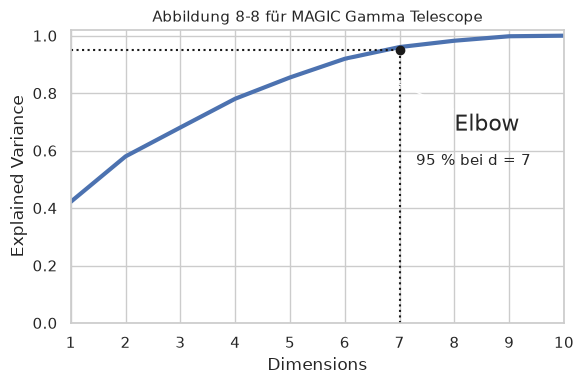

Elbow bei 6 Komponenten (kumuliert 0.920); 95 %-Schwelle bei d = 7.


In [6]:
# Elbow = Punkt der Kurve mit größtem Abstand zur Sehne (erster -> letzter Punkt)
xs = np.arange(1, len(cumsum) + 1)
p1, p2 = np.array([xs[0], cumsum[0]]), np.array([xs[-1], cumsum[-1]])
vec = (p2 - p1) / np.linalg.norm(p2 - p1)
pts = np.column_stack([xs, cumsum]) - p1
dist = np.abs(pts[:, 0] * vec[1] - pts[:, 1] * vec[0])
elbow = int(xs[np.argmax(dist)])

# --- Abbildung 8-8 (Code nach ageron/handson-ml2, angepasst auf 10 Dimensionen) ---
plt.figure(figsize=(6, 4))
plt.plot(xs, cumsum, linewidth=3)
plt.axis([1, len(cumsum), 0, 1.02])
plt.xlabel("Dimensions")
plt.ylabel("Explained Variance")
plt.plot([d, d], [0, 0.95], "k:")
plt.plot([1, d], [0.95, 0.95], "k:")
plt.plot(d, 0.95, "ko")
plt.annotate("Elbow", xy=(elbow, cumsum[elbow - 1]), xytext=(elbow + 2, cumsum[elbow - 1] - 0.25),
             arrowprops=dict(arrowstyle="->"), fontsize=16)
plt.annotate(f"95 % bei d = {d}", xy=(d, 0.95), xytext=(d + 0.3, 0.55), fontsize=11)
plt.xticks(xs)
plt.grid(True)
plt.title("Abbildung 8-8 für MAGIC Gamma Telescope", fontsize=11)
plt.tight_layout()
plt.savefig("abb_8_8_explained_variance.png", dpi=150)
plt.show()
print(f"Elbow bei {elbow} Komponenten (kumuliert {cumsum[elbow-1]:.3f}); 95 %-Schwelle bei d = {d}.")

Zusätzlich zur geforderten Abbildung zeigen wir, **woraus** die Hauptkomponenten bestehen (Ladungen der Features) und wie sich die Varianz pro Komponente verteilt (Scree-Plot). Das hilft bei der Interpretation der Diskussion weiter unten.

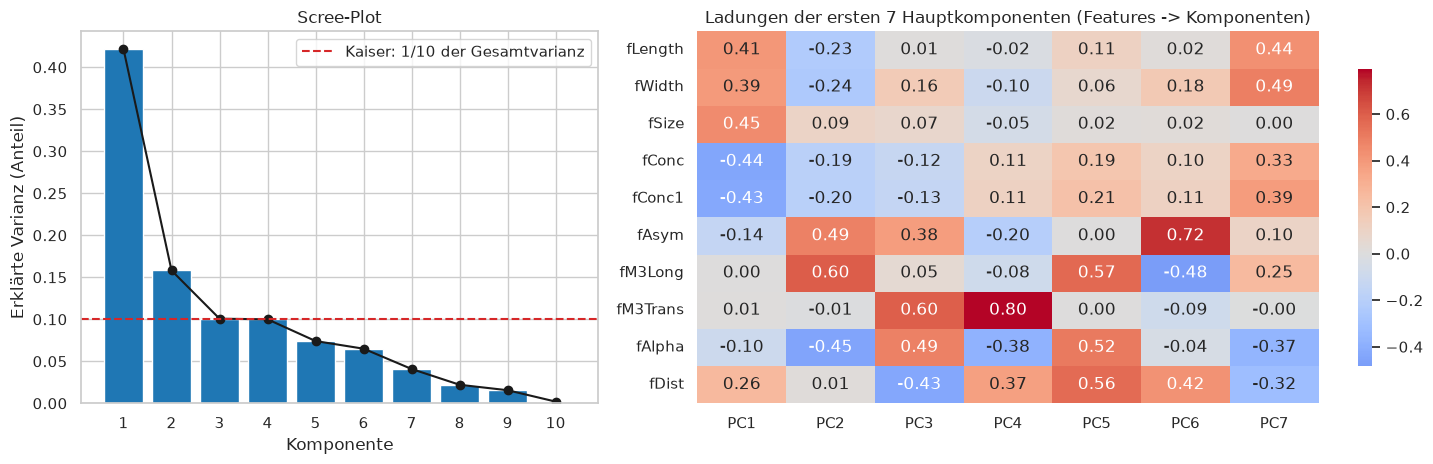

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})

axes[0].bar(xs, evr, color="tab:blue")
axes[0].plot(xs, evr, "ko-")
axes[0].axhline(1 / len(evr), color="tab:red", ls="--", label="Kaiser: 1/10 der Gesamtvarianz")
axes[0].set_xlabel("Komponente"); axes[0].set_ylabel("Erklärte Varianz (Anteil)")
axes[0].set_title("Scree-Plot"); axes[0].set_xticks(xs); axes[0].legend()

loadings = pd.DataFrame(pca_full.components_[:d].T, index=FEATURES,
                        columns=[f"PC{i+1}" for i in range(d)])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1],
            cbar_kws={"shrink": .8})
axes[1].set_title(f"Ladungen der ersten {d} Hauptkomponenten (Features -> Komponenten)")
plt.tight_layout(); plt.show()

## 5. Vergleich ohne und mit PCA

### 5.1 Modellqualität auf den Validierungsdaten

Alle vier Pipelines werden auf den Trainingsdaten gefittet und auf den (nie gesehenen) Validierungsdaten bewertet. Neben Accuracy zählen wegen der Klassenimbalance (65 % `g` zu 35 % `h`) vor allem **F1, MCC und ROC-AUC**. Der Einzelsplit ist eine Momentaufnahme, deshalb folgt in 5.2 zusätzlich eine 5-fach-Kreuzvalidierung.

In [8]:
pipes = {"RF ohne PCA": rf_base, "RF mit PCA": rf_pca,
         "kNN ohne PCA": knn_base, "kNN mit PCA": knn_pca}
MET = ["Accuracy", "Precision", "Recall", "F1", "MCC", "ROC-AUC"]

fitted, rows = {}, []
for name, mk in pipes.items():
    p = mk().fit(X_train, y_train)
    fitted[name] = p
    r = quality(p, X_val, y_val)
    r["Dimensionen"] = p.named_steps["pca"].n_components_ if "pca" in p.named_steps else X.shape[1]
    rows.append(pd.Series(r, name=name))
qual = pd.DataFrame(rows)

display(qual.style.format({c: "{:.4f}" for c in MET})
        .format({"Dimensionen": "{:.0f}"})
        .background_gradient(cmap="Greens", subset=["F1", "MCC", "ROC-AUC"]))

# Änderung durch PCA (in Prozentpunkten)
delta = pd.DataFrame({
    "RF":  (qual.loc["RF mit PCA", MET] - qual.loc["RF ohne PCA", MET]) * 100,
    "kNN": (qual.loc["kNN mit PCA", MET] - qual.loc["kNN ohne PCA", MET]) * 100})
print("\nÄnderung durch PCA in Prozentpunkten (mit minus ohne):")
display(delta.style.format("{:+.2f}"))

,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,Dimensionen
RF ohne PCA,0.876223,0.900561,0.910787,0.905645,0.725898,0.934124,10
RF mit PCA,0.804814,0.853519,0.845904,0.849695,0.571477,0.882400,7
kNN ohne PCA,0.845808,0.828163,0.963504,0.890722,0.655264,0.898440,10
kNN mit PCA,0.806665,0.807515,0.923763,0.861736,0.558989,0.863282,7



Änderung durch PCA in Prozentpunkten (mit minus ohne):


,RF,kNN
Accuracy,-7.14,-3.91
Precision,-4.70,-2.06
Recall,-6.49,-3.97
F1,-5.60,-2.90
MCC,-15.44,-9.63
ROC-AUC,-5.17,-3.52


### 5.2 Robustheit: 5-fach-Kreuzvalidierung (PCA liegt in der Pipeline, kein Leakage)

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, mk in pipes.items():
    t0 = time.perf_counter()
    s = cross_val_score(mk(), X_train, y_train, cv=skf, scoring="f1")
    cv_rows.append({"Modell": name, "F1 (CV Mittel)": s.mean(), "F1 (CV Std)": s.std(),
                    "Min": s.min(), "Max": s.max(), "CV-Dauer [s]": time.perf_counter() - t0})
cv_df = pd.DataFrame(cv_rows).set_index("Modell")
display(cv_df.style.format({"F1 (CV Mittel)": "{:.4f}", "F1 (CV Std)": "{:.4f}", "Min": "{:.4f}",
                            "Max": "{:.4f}", "CV-Dauer [s]": "{:.1f}"}))

,F1 (CV Mittel),F1 (CV Std),Min,Max,CV-Dauer [s]
Modell,,,,,
RF ohne PCA,0.9046,0.0031,0.9005,0.9078,16.1
RF mit PCA,0.8582,0.0028,0.8543,0.8626,10.8
kNN ohne PCA,0.8860,0.0027,0.8817,0.8898,1.3
kNN mit PCA,0.8654,0.0025,0.8628,0.8691,0.6


### 5.3 Zeitmessung

Wir messen mit `time.perf_counter()`, **jede Messung 7-mal wiederholt** und bewerten den **Median** (robust gegen Ausreißer durch andere Prozesse auf der Maschine). Gemessen wird die **gesamte Pipeline**, also bei den PCA-Varianten inklusive Standardisieren und PCA-Fit bzw. -Transform. Alles andere wäre unfair, denn die PCA kostet selbst Zeit.

* **Fit-Zeit:** `pipe.fit(X_train, y_train)` (15 124 Zeilen)
* **Predict-Zeit:** `pipe.predict(X_val)` (3 781 Zeilen)

Beim **k-NN** ist die Fit-Zeit fast null (er speichert nur die Daten, "lazy learner"), die Arbeit steckt im Vorhersagen. Beim **Random Forest** ist es umgekehrt.

In [10]:
N_REP = 7

def timed(fn):
    t0 = time.perf_counter(); out = fn(); return time.perf_counter() - t0, out

time_rows = []
for name, mk in pipes.items():
    fit_t, pred_t = [], []
    for _ in range(N_REP):
        p = mk()
        t, _ = timed(lambda: p.fit(X_train, y_train)); fit_t.append(t)
        t, _ = timed(lambda: p.predict(X_val));        pred_t.append(t)
    time_rows.append({"Modell": name,
                      "Fit Median [s]": np.median(fit_t), "Fit Std [s]": np.std(fit_t),
                      "Predict Median [s]": np.median(pred_t), "Predict Std [s]": np.std(pred_t),
                      "Predict je 1000 Zeilen [ms]": np.median(pred_t) / len(X_val) * 1e6})
tm = pd.DataFrame(time_rows).set_index("Modell")
tm["Fit+Predict [s]"] = tm["Fit Median [s]"] + tm["Predict Median [s]"]
display(tm.style.format("{:.4f}"))

print("\nVeränderung durch PCA (Faktor; < 1 heißt schneller mit PCA):")
for m in ["RF", "kNN"]:
    a, b = tm.loc[f"{m} ohne PCA"], tm.loc[f"{m} mit PCA"]
    print(f"  {m:3s}: Fit x{b['Fit Median [s]']/a['Fit Median [s]']:.2f} | "
          f"Predict x{b['Predict Median [s]']/a['Predict Median [s]']:.2f} | "
          f"Fit+Predict x{b['Fit+Predict [s]']/a['Fit+Predict [s]']:.2f}")

,Fit Median [s],Fit Std [s],Predict Median [s],Predict Std [s],Predict je 1000 Zeilen [ms],Fit+Predict [s]
Modell,,,,,,
RF ohne PCA,3.8344,0.2424,0.0647,0.0159,17.1193,3.8991
RF mit PCA,2.6068,0.0609,0.0746,0.0094,19.7259,2.6814
kNN ohne PCA,0.0165,0.0009,0.3771,0.0352,99.7335,0.3936
kNN mit PCA,0.0137,0.0002,0.1549,0.0057,40.9588,0.1686



Veränderung durch PCA (Faktor; < 1 heißt schneller mit PCA):
  RF : Fit x0.68 | Predict x1.15 | Fit+Predict x0.69
  kNN: Fit x0.83 | Predict x0.41 | Fit+Predict x0.43


Aufschlüsselung: Was kostet die PCA selbst, und was spart das nachfolgende Modell?

In [11]:
# Kosten der Vorverarbeitung allein (Scaler + PCA)
t_fit, t_tr = [], []
for _ in range(N_REP):
    pre = Pipeline([("scaler", StandardScaler()),
                    ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE))])
    t, _ = timed(lambda: pre.fit(X_train)); t_fit.append(t)
    t, _ = timed(lambda: pre.transform(X_val)); t_tr.append(t)
print(f"Scaler + PCA fit      : {np.median(t_fit)*1000:7.2f} ms (Median)")
print(f"Scaler + PCA transform: {np.median(t_tr)*1000:7.2f} ms (Median, {len(X_val)} Zeilen)")

# Reine Modellzeit (ohne Vorverarbeitung) auf bereits transformierten Daten
Xtr_p, Xva_p = pre.transform(X_train), pre.transform(X_val)
Xtr_s, Xva_s = scaler.transform(X_train), scaler.transform(X_val)
def clf_times(mk, Xa, Xb):
    f, p = [], []
    for _ in range(N_REP):
        c = mk()
        t, _ = timed(lambda: c.fit(Xa, y_train)); f.append(t)
        t, _ = timed(lambda: c.predict(Xb));      p.append(t)
    return np.median(f), np.median(p)

res = {"RF  (Rohdaten, 10 Dim.)": clf_times(make_rf, X_train.values, X_val.values),
       f"RF  (PCA, {d} Dim.)": clf_times(make_rf, Xtr_p, Xva_p),
       "kNN (standardisiert, 10 Dim.)": clf_times(make_knn, Xtr_s, Xva_s),
       f"kNN (PCA, {d} Dim.)": clf_times(make_knn, Xtr_p, Xva_p)}
core = pd.DataFrame(res, index=["Fit [s]", "Predict [s]"]).T
print("\nReine Klassifikator-Zeit ohne Vorverarbeitung:")
display(core.style.format("{:.4f}"))

Scaler + PCA fit      :    3.29 ms (Median)
Scaler + PCA transform:    1.16 ms (Median, 3781 Zeilen)



Reine Klassifikator-Zeit ohne Vorverarbeitung:


,Fit [s],Predict [s]
"RF (Rohdaten, 10 Dim.)",3.5468,0.0646
"RF (PCA, 7 Dim.)",2.6183,0.0742
"kNN (standardisiert, 10 Dim.)",0.0131,0.3257
"kNN (PCA, 7 Dim.)",0.0099,0.1513


### 5.4 Zeit gegen Qualität auf einen Blick

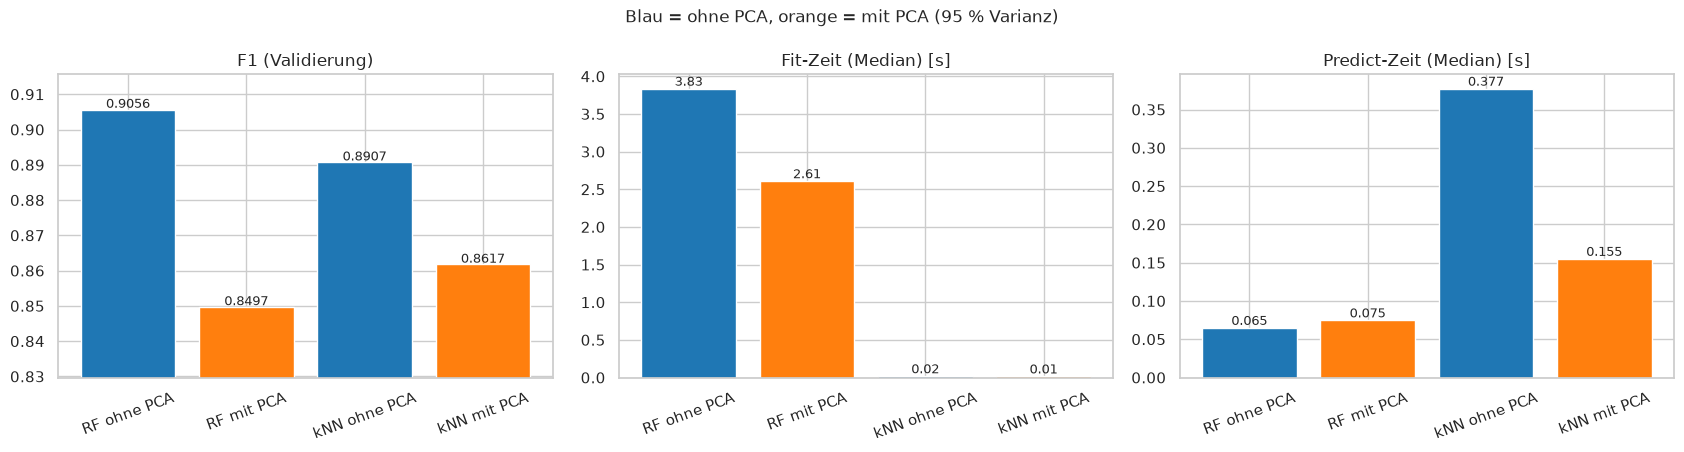

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
names = list(pipes.keys())
colors = ["tab:blue", "tab:orange", "tab:blue", "tab:orange"]

axes[0].bar(names, qual["F1"], color=colors)
axes[0].set_ylim(qual["F1"].min() - 0.02, qual["F1"].max() + 0.01)
axes[0].set_title("F1 (Validierung)"); axes[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(qual["F1"]): axes[0].text(i, v + 0.0005, f"{v:.4f}", ha="center", fontsize=9)

axes[1].bar(names, tm["Fit Median [s]"], color=colors)
axes[1].set_title("Fit-Zeit (Median) [s]"); axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(tm["Fit Median [s]"]): axes[1].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)

axes[2].bar(names, tm["Predict Median [s]"], color=colors)
axes[2].set_title("Predict-Zeit (Median) [s]"); axes[2].tick_params(axis="x", rotation=20)
for i, v in enumerate(tm["Predict Median [s]"]): axes[2].text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

fig.suptitle("Blau = ohne PCA, orange = mit PCA (95 % Varianz)", fontsize=12)
plt.tight_layout(); plt.show()

## 6. Zusatzanalysen

### 6.1 Wie hängen Qualität und Zeit von der Komponentenzahl ab?

Die 95 %-Regel ist eine Konvention. Um zu sehen, ob sie hier sinnvoll sitzt, trainieren wir beide Modelle mit 1 bis 10 Komponenten (bei 10 Komponenten ist es reine Rotation ohne Informationsverlust).

Modell,Kumulierte Varianz,F1 RF,F1 kNN
k,,,
1,0.4217,0.6748,0.7217
2,0.5798,0.7630,0.8000
3,0.6805,0.8014,0.8251
4,0.7805,0.8167,0.8373
5,0.8546,0.8459,0.8599
6,0.9196,0.8533,0.8648
7,0.9604,0.8497,0.8617
8,0.9825,0.8623,0.8676
9,0.9980,0.8895,0.8896


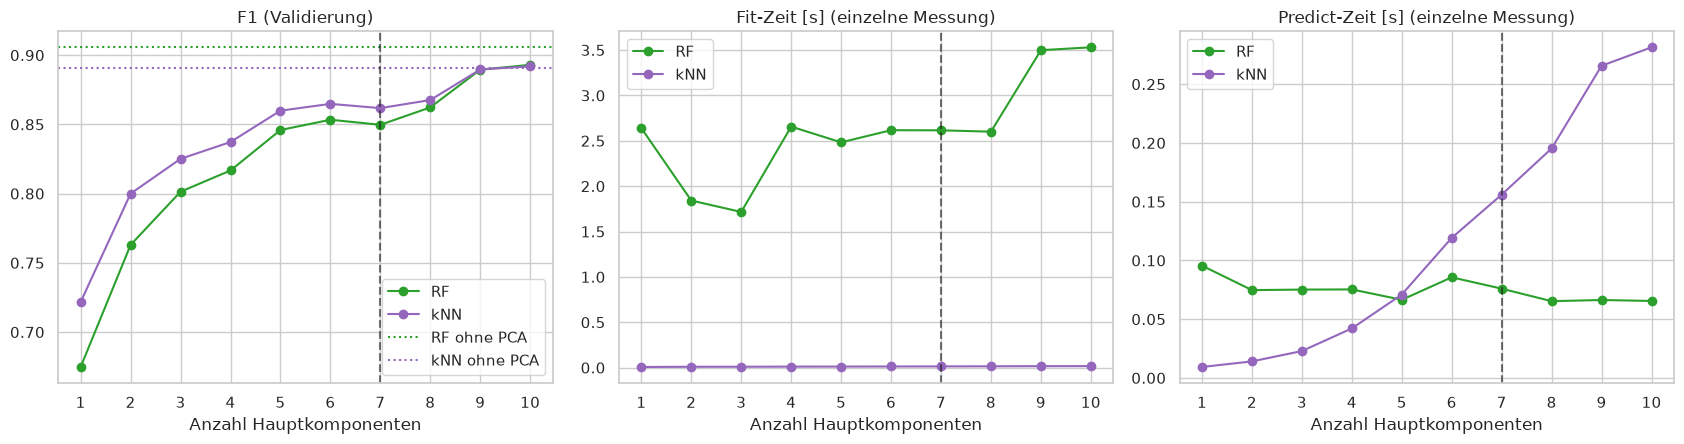

In [13]:
sweep = []
for k in range(1, X.shape[1] + 1):
    for name, mk in [("RF", make_rf), ("kNN", make_knn)]:
        pp = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=k, random_state=RANDOM_STATE)),
                       ("clf", mk())])
        ft, _ = timed(lambda: pp.fit(X_train, y_train))
        pt, pred = timed(lambda: pp.predict(X_val))
        sweep.append({"k": k, "Modell": name, "F1": f1_score(y_val, pred),
                      "MCC": matthews_corrcoef(y_val, pred),
                      "Fit [s]": ft, "Predict [s]": pt, "Varianz": cumsum[k - 1]})
sw = pd.DataFrame(sweep)

piv = sw.pivot(index="k", columns="Modell", values="F1").rename(columns={"RF": "F1 RF", "kNN": "F1 kNN"})
piv.insert(0, "Kumulierte Varianz", cumsum[:len(piv)])
display(piv[["Kumulierte Varianz", "F1 RF", "F1 kNN"]].style.format("{:.4f}"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for name, col in [("RF", "tab:green"), ("kNN", "tab:purple")]:
    s = sw[sw["Modell"] == name]
    axes[0].plot(s["k"], s["F1"], "o-", color=col, label=name)
    axes[1].plot(s["k"], s["Fit [s]"], "o-", color=col, label=name)
    axes[2].plot(s["k"], s["Predict [s]"], "o-", color=col, label=name)
axes[0].axhline(qual.loc["RF ohne PCA", "F1"], color="tab:green", ls=":", label="RF ohne PCA")
axes[0].axhline(qual.loc["kNN ohne PCA", "F1"], color="tab:purple", ls=":", label="kNN ohne PCA")
for ax, t in zip(axes, ["F1 (Validierung)", "Fit-Zeit [s] (einzelne Messung)", "Predict-Zeit [s] (einzelne Messung)"]):
    ax.axvline(d, color="k", ls="--", alpha=.6); ax.set_xlabel("Anzahl Hauptkomponenten"); ax.set_title(t)
    ax.set_xticks(range(1, 11)); ax.legend()
plt.tight_layout(); plt.show()

### 6.2 Ändert Re-Tuning etwas?

Die Hyperparameter wurden im Originalraum optimiert. Im PCA-Raum könnten andere Werte besser sein. Wir wiederholen daher dieselben `GridSearchCV`-Läufe (selbe Gitter wie im Miniprojekt, cv=5, Scoring F1) auf den PCA-Daten und vergleichen mit den übernommenen Parametern. Das ist auch eine Zeitmessung für den **gesamten Optimierungsaufwand**, der in der Praxis oft wichtiger ist als eine einzelne Fit-Zeit.

Für faire Zeiten parallelisiert nur die Grid-Search (`n_jobs=-1`), der Random Forest läuft darin mit `n_jobs=1`. Sonst würden sich beide Ebenen die CPU-Kerne gegenseitig wegnehmen.

In [14]:
grids = {
    "RF":  (rf_pca,  {"clf__n_estimators": [200, 400], "clf__max_depth": [10, 20, None], "clf__min_samples_leaf": [1, 5]}),
    "kNN": (knn_pca, {"clf__n_neighbors": [5, 11, 21, 31], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}),
}
grids_base = {
    "RF":  (rf_base,  grids["RF"][1]),
    "kNN": (knn_base, grids["kNN"][1]),
}
tune_rows, tuned = [], {}
for variant, gdict in [("ohne PCA", grids_base), ("mit PCA", grids)]:
    for m, (mk, pg) in gdict.items():
        t0 = time.perf_counter()
        est = mk(n_jobs=1) if m == "RF" else mk()
        gs = GridSearchCV(est, pg, cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
        el = time.perf_counter() - t0
        tuned[(m, variant)] = gs
        r = quality(gs.best_estimator_, X_val, y_val)
        tune_rows.append({"Modell": f"{m} {variant}", "Grid-Search [s]": el, "CV-F1": gs.best_score_,
                          "Val-F1": r["F1"], "Val-MCC": r["MCC"],
                          "Beste Parameter": str({k.replace("clf__", ""): v for k, v in gs.best_params_.items()})})
tune = pd.DataFrame(tune_rows).set_index("Modell")
pd.set_option("display.max_colwidth", 120)
display(tune.style.format({"Grid-Search [s]": "{:.1f}", "CV-F1": "{:.4f}", "Val-F1": "{:.4f}", "Val-MCC": "{:.4f}"}))

,Grid-Search [s],CV-F1,Val-F1,Val-MCC,Beste Parameter
Modell,,,,,
RF ohne PCA,126.6,0.9037,0.9056,0.7259,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}"
kNN ohne PCA,4.8,0.8867,0.8907,0.6553,"{'n_neighbors': 11, 'p': 1, 'weights': 'distance'}"
RF mit PCA,98.4,0.8627,0.8497,0.5715,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}"
kNN mit PCA,2.6,0.8671,0.8689,0.5790,"{'n_neighbors': 31, 'p': 2, 'weights': 'distance'}"


### 6.3 Warum fällt die Qualität? Varianz ist nicht gleich Klasseninformation

PCA ist **unüberwacht**: Sie kennt das Label nicht und sortiert Komponenten nur nach Varianz. Ob eine Komponente die Klassen `g` und `h` trennt, steht auf einem anderen Blatt. Das prüfen wir mit dem ANOVA-F-Wert (derselbe wie im Miniprojekt für die Features) je Hauptkomponente auf den Trainingsdaten. Hoher F-Wert bedeutet starke Klassentrennung.

,Varianz [%],kumuliert [%],ANOVA-F (Klassentrennung),im 95 %-Modell behalten
PC1,42.17,42.17,317.3,ja
PC2,15.81,57.98,3176.0,ja
PC3,10.07,68.05,508.6,ja
PC4,10.00,78.05,323.5,ja
PC5,7.41,85.46,979.5,ja
PC6,6.50,91.96,32.3,ja
PC7,4.08,96.04,0.0,ja
PC8,2.20,98.25,163.8,NEIN
PC9,1.56,99.80,108.2,NEIN
PC10,0.20,100.00,11.1,NEIN


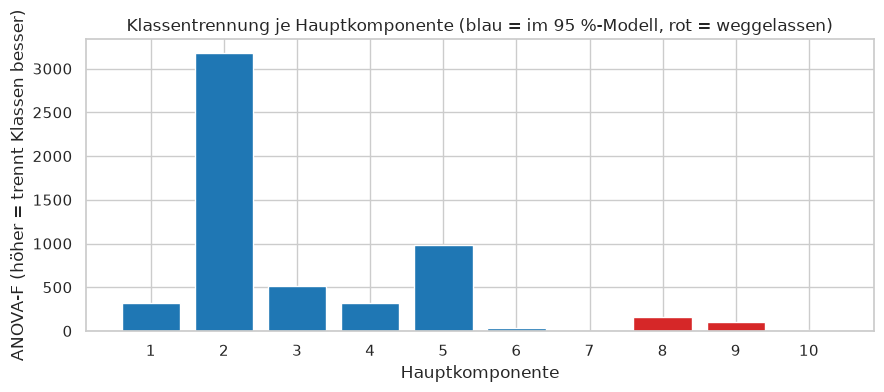

Ladungen der weggelassenen Komponenten:


,PC8,PC9,PC10
fLength,0.76,0.07,0.02
fWidth,-0.55,-0.42,-0.01
fSize,-0.30,0.82,0.11
fConc,-0.07,0.15,0.75
fConc1,-0.10,0.32,-0.65
fAsym,0.14,0.01,-0.00
fM3Long,-0.03,-0.09,0.00
fM3Trans,0.01,0.00,0.00
fAlpha,0.03,0.04,-0.01
fDist,-0.02,-0.11,-0.01


In [ ]:

from sklearn.feature_selection import f_classif

Z_train = pca_full.transform(X_train_s)             # alle 10 Komponenten
f_pc, _ = f_classif(Z_train, y_train)
pc_tab = pd.DataFrame({"Varianz [%]": evr * 100, "kumuliert [%]": cumsum * 100, "ANOVA-F (Klassentrennung)": f_pc,
                       "im 95 %-Modell behalten": ["ja" if i < d else "NEIN" for i in range(len(evr))]},
                      index=[f"PC{i+1}" for i in range(len(evr))])
display(pc_tab.style.format({"Varianz [%]": "{:.2f}", "kumuliert [%]": "{:.2f}", "ANOVA-F (Klassentrennung)": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 11), f_pc, color=["tab:blue" if i < d else "tab:red" for i in range(10)])
ax.set_xticks(range(1, 11)); ax.set_xlabel("Hauptkomponente"); ax.set_ylabel("ANOVA-F (höher = trennt Klassen besser)")
ax.set_title("Klassentrennung je Hauptkomponente (blau = im 95 %-Modell, rot = weggelassen)")
plt.tight_layout(); plt.show()

load = pd.DataFrame(pca_full.components_[7:].T, index=FEATURES, columns=["PC8", "PC9", "PC10"]).round(2)
print("Ladungen der weggelassenen Komponenten:")
display(load)


## 7. Diskussion

### 7.1 Ergebnisse auf einen Blick

PCA mit 95 % Varianz reduziert die 10 Features auf **7 Hauptkomponenten** (96,0 % Varianz). Alle Zahlen stammen aus den Läufen oben (Validierungsdaten, derselbe Split wie im Miniprojekt).

| | F1 | MCC | ROC-AUC | Fit [s] | Predict [s] (3 781 Zeilen) | Grid-Search [s] |
|---|---|---|---|---|---|---|
| **RF ohne PCA** | 0,9056 | 0,726 | 0,934 | 3,83 | 0,065 | 126,6 |
| **RF mit PCA** | 0,8497 | 0,571 | 0,882 | 2,61 | 0,075 | 98,4 |
| **kNN ohne PCA** | 0,8907 | 0,655 | 0,898 | 0,017 | 0,377 | 4,8 |
| **kNN mit PCA** | 0,8617 | 0,559 | 0,863 | 0,014 | 0,155 | 2,6 |

### 7.2 Auswirkung auf die Modellqualität: deutlich schlechter

* **Random Forest:** F1 sinkt um 5,6 Prozentpunkte, der MCC sogar um 15,4 Prozentpunkte (0,726 auf 0,571). Die 5-fach-Kreuzvalidierung bestätigt das: F1 0,9046 auf 0,8582 bei einer Streuung von nur etwa 0,003 zwischen den Folds.
* **k-NN:** F1 sinkt um 2,9 Prozentpunkte, der MCC um 9,6 Prozentpunkte. Kreuzvalidiert: 0,8860 auf 0,8654.
* **Das ist kein Zufall.** Wie stark der Random Forest allein durch Zufall schwankt, haben wir in Abschnitt 2 mit 5 Seeds gemessen (Std 0,0006). Die Verschlechterung ist rund 90-mal so groß. Ein kleiner Hinweis zur Ehrlichkeit: Unser Neuaufbau liefert für den RF ohne PCA F1 0,9051 ± 0,0006, das Miniprojekt nennt 0,9106. Das liegt vermutlich an anderen Softwareversionen und ändert nichts an der Aussage, weil beide Varianten hier unter identischen Bedingungen verglichen werden.
* **Der MCC reagiert am stärksten.** Er berücksichtigt alle vier Felder der Konfusionsmatrix und ist bei unserer Klassenimbalance (65 % `g`) das ehrlichste Maß. Dass F1 weniger fällt als der MCC, liegt daran, dass F1 die Mehrheitsklasse `g` bevorzugt.

### 7.3 Warum? Varianz ist nicht gleich Klasseninformation

Die 95 %-Regel behält die Richtungen mit der meisten **Varianz**, ohne das Label zu kennen. Abschnitt 6.3 zeigt, dass das hier schiefgeht:

* **PC7**, die letzte behaltene Komponente, hat einen ANOVA-F-Wert von nur **0,04**, sie trennt `g` und `h` praktisch gar nicht.
* **PC8** (F = 164) und **PC9** (F = 108) trennen die Klassen dagegen deutlich, wurden aber verworfen, weil sie nur 2,2 % bzw. 1,6 % der Varianz tragen. Laut den Ladungen sind das Kontraste zwischen Formmerkmalen (`fLength` gegen `fWidth`, `fSize` gegen `fWidth`), also Informationen über die Form des Schauers, die für die Unterscheidung Gamma/Hadron physikalisch Sinn ergeben.
* **Die Komponentenzahl-Kurve in 6.1 bestätigt das:** Von 7 auf 9 Komponenten springt F1 beim RF von 0,850 auf 0,890 und beim kNN von 0,862 auf 0,890, obwohl nur 3,8 % Varianz dazukommen. Bei 9 Komponenten (99,8 % Varianz) ist das kNN auf Niveau von "ohne PCA" (0,8896 gegen 0,8907).
* **Der Random Forest leidet zusätzlich unter der Rotation selbst.** Mit allen 10 Komponenten (also ganz ohne Informationsverlust, nur gedrehte Achsen) erreicht der RF F1 0,893 statt 0,9056, das sind 1,3 Prozentpunkte Verlust. Das kNN verliert dabei nichts (0,8919 gegen 0,8907). Plausible Erklärung: Bäume schneiden achsenparallel. Auf den Original-Features, etwa `fAlpha`, genügt ein einziger Schnitt. Nach der PCA sind die Features zu Mischungen verschmolzen, und derselbe Zusammenhang braucht mehrere Schnitte. Distanzbasierte Verfahren wie kNN ändert eine reine Drehung dagegen nicht. Das ist eine Interpretation, die wir nicht eigens gegengeprüft haben.
* **Re-Tuning hilft nicht** (Abschnitt 6.2): Der RF behält dieselben besten Parameter, CV-F1 0,8627. Das kNN wählt mit PCA ein größeres k (31) und Euklid-Distanz, kommt aber nur auf 0,8689 (Validierung) gegen 0,8907 ohne PCA. Der Verlust ist also kein Tuning-Artefakt, sondern Informationsverlust.

### 7.4 Auswirkung auf die Performance (Zeit)

Gemessen wurde die gesamte Pipeline (Median aus 7 Läufen), die PCA ist also eingerechnet. Sie selbst kostet nur etwa 3,3 ms (Fit) und 1,2 ms (Transform für 3 781 Zeilen) und fällt nicht ins Gewicht.

* **Random Forest, Training:** 3,83 s auf 2,61 s, also Faktor 0,68 (rund 32 % schneller). Mögliche Ursache: Der RF betrachtet pro Split nur `sqrt(Anzahl Features)` Kandidaten, bei 7 statt 10 Features also weniger, und jeder Split ist billiger. Die gesamte Grid-Search wird von 127 s auf 98 s kürzer.
* **Random Forest, Vorhersage:** praktisch unverändert (0,065 s gegen 0,075 s). Die Differenz liegt in der Größenordnung der Messstreuung (0,01 bis 0,016 s) und ist nicht belastbar.
* **k-NN, Vorhersage:** 0,377 s auf 0,155 s, Faktor 0,41, also rund **2,4-mal schneller**. kNN rechnet bei jeder Vorhersage Abstände zu den Trainingspunkten, weniger Dimensionen bedeuten billigere Abstände und effizientere Suchstrukturen. Das Training ist bei kNN in beiden Fällen vernachlässigbar (nur Daten merken). Die Grid-Search halbiert sich fast (4,8 s auf 2,6 s).
* **Einordnung:** Das sind Sekundenbruchteile auf 15 000 Zeilen. In absoluten Zahlen spart PCA hier 1,2 s beim RF-Training und 0,22 s beim Vorhersagen von 3 781 Zeilen mit kNN. Die Zeitgewinne sind real, aber bei dieser Datenmenge klein. Sie würden erst bei sehr vielen Zeilen oder Features oder bei strengen Latenzvorgaben relevant. Die absoluten Zeiten gelten nur für diese Maschine (4 Kerne, virtuelle Maschine), die Verhältnisse sind aussagekräftiger als die Sekunden.

### 7.5 Abbildung 8-8: Wie viel lässt sich überhaupt komprimieren?

Die Kurve in Abschnitt 4 steigt bei uns vergleichsweise gleichmäßig an: PC1 erklärt 42 %, danach folgen 16 %, 10 %, 10 %, 7 %, 6,5 % und 4 %. Einen scharfen Knick gibt es nicht wirklich, der objektiv bestimmte "Elbow" liegt bei 6 Komponenten (92 %), die 95 %-Schwelle bei 7. Die Dimension sinkt damit nur um 30 % (10 auf 7). Beim MNIST-Beispiel im Buch reichen für 95 % dagegen grob 150 von 784 Dimensionen, also etwa 80 % weniger. Der Grund: Unsere 10 Hillas-Parameter sind nur teilweise redundant (`fConc` und `fConc1` korrelieren mit etwa 0,97, `fLength`, `fWidth` und `fSize` hängen zusammen), die meisten tragen aber eigene Information. Wenig Redundanz heißt wenig Kompressionspotenzial, und hier kommt hinzu, dass die wenigen "überflüssigen" Richtungen ausgerechnet Klasseninformation enthalten.

### 7.6 Fazit

1. **PCA mit 95 % ist für dieses Problem nicht empfehlenswert.** Der RF verliert 5,6 Prozentpunkte F1 (MCC 15 Punkte) für 32 % kürzeres Training, das kNN verliert 2,9 Punkte F1 für 2,4-fach schnelleres Vorhersagen. Bei Datenmengen, die ohnehin in Sekundenbruchteilen laufen, ist das ein schlechter Tausch.
2. **Die Ursache ist grundsätzlich:** PCA wählt nach Varianz, nicht nach Nutzen für die Klassifikation. Hier liegt die trennende Information teils in kleinen Varianzanteilen.
3. **Wenn man PCA trotzdem will:** Die Schwelle hochsetzen (bei 99 % Varianz, also 9 Komponenten, geht beim kNN nichts verloren, beim RF etwa 1,6 Punkte), oder überwachte Verfahren verwenden (z. B. Feature-Auswahl nach F-Wert wie im Miniprojekt, oder LDA).
4. **Die besten Modelle bleiben die aus dem Miniprojekt:** RF und kNN auf den ursprünglichen, standardisierten bzw. unskalierten Features, ohne PCA.

**Grenzen dieser Untersuchung:** Die Aussagen beruhen auf einem einzelnen Train/Validation-Split (durch 5-fach-CV und 5-Seeds-Test abgesichert), es gibt keine formalen Signifikanztests, und die Zeitmessungen gelten nur für diese Maschine. Die Erklärungen zu Laufzeit-Ursachen und zur Rotation beim RF sind plausible Interpretationen, keine eigens bewiesenen Tatsachen.